# Experiment 8: Introduction to Neural Networks with Keras

---
### **Aim / Objective:**
To build, compile, and train a Multi-Layer Perceptron (MLP) using TensorFlow/Keras, understanding dense layers, activation functions, loss functions, and optimizers.

---
### **Theory & Overview:**
Artificial Neural Networks (ANNs) consist of:
- **Input Layer**: Ingests feature vectors.
- **Dense / Fully-Connected Layers**: Computes linear transformations $z = \mathbf{W}\mathbf{x} + \mathbf{b}$ followed by non-linear activations (ReLU, Sigmoid).
- **Loss Functions**: Quantifies model error (e.g., Sparse Categorical Cross-Entropy, Binary Cross-Entropy).
- **Optimizers**: Adam, RMSprop, or SGD updating weights using gradient descent.



### **1. Dataset Preparation & Normalization**


In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'
import keras
from keras import layers
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Generate synthetic multi-class tabular dataset
X, y = make_classification(n_samples=1500, n_features=20, n_informative=12,
                           n_classes=3, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Train samples: {X_train.shape[0]}, Features: {X_train.shape[1]}, Classes: 3")



Train samples: 1200, Features: 20, Classes: 3


### **2. Building the Feedforward Neural Network Architecture**


In [2]:
model = keras.Sequential([
    layers.Input(shape=(20,)),
    layers.Dense(64, activation='relu', name='Hidden_Layer_1'),
    layers.Dropout(0.2, name='Dropout_1'),
    layers.Dense(32, activation='relu', name='Hidden_Layer_2'),
    layers.Dense(3, activation='softmax', name='Output_Layer')
])

model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,523 (13.76 KB)

 Trainable params: 3,523 (13.76 KB)

 Non-trainable params: 0 (0.00 B)

### **3. Model Compilation & Training**


In [3]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=32,
    verbose=1
)



Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4625 - loss: 1.0498 - val_accuracy: 0.6292 - val_loss: 0.9205
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5927 - loss: 0.9017 - val_accuracy: 0.7042 - val_loss: 0.8087
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6635 - loss: 0.8047 - val_accuracy: 0.7625 - val_loss: 0.7229
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6896 - loss: 0.7350 - val_accuracy: 0.7625 - val_loss: 0.6587
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7188 - loss: 0.6796 - val_accuracy: 0.7958 - val_loss: 0.6093
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7542 - loss: 0.6175 - val_accuracy: 0.7917 - val_loss: 0.5824
Epoch 7/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7729 - loss: 0.5700 - val_accuracy: 0.7792 - val_loss: 0.5607
Epoch 8/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7521 - loss: 0.5702 - val_accuracy: 0.7833 - v

### **4. Evaluating Performance & Plotting Learning Curves**



--- Test Results ---
Test Loss: 0.3814 | Test Accuracy: 84.67%


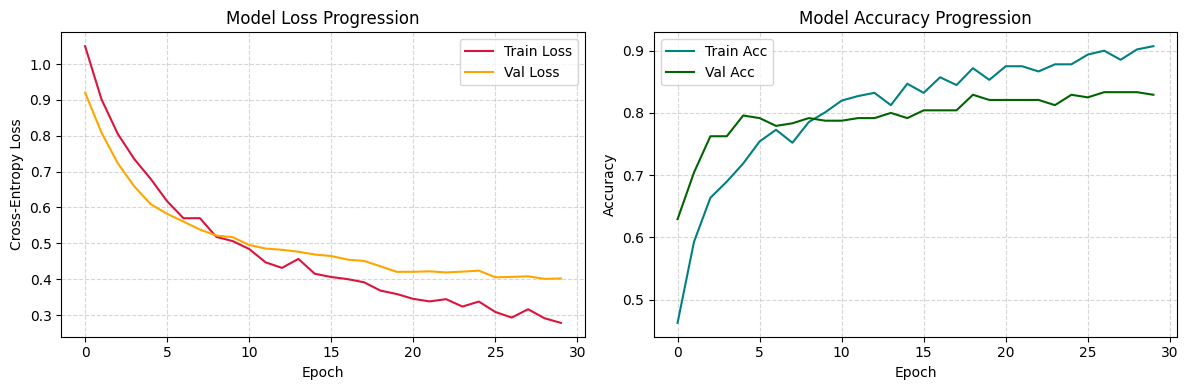

In [4]:
import matplotlib.pyplot as plt

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\n--- Test Results ---")
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc*100:.2f}%")

# Plot Loss and Accuracy curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss', color='crimson')
plt.plot(history.history['val_loss'], label='Val Loss', color='orange')
plt.title("Model Loss Progression")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Acc', color='teal')
plt.plot(history.history['val_accuracy'], label='Val Acc', color='darkgreen')
plt.title("Model Accuracy Progression")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()



---
### **Conclusion & Learning Outcomes:**
Constructed a multi-layer feedforward neural network in Keras, calibrated hyperparameters with the Adam optimizer, and monitored convergence via training/validation loss curves.
